# Figure S2: density change of the densest HLNA water in 2xCO2 and 4xCO2

The same calculation as Figure 4, for a) 2xCO2 and b) 4xCO2, with shared x and y axes.

Inputs: `FMAASOmean_sigma1_cells_{2x,4x}_natl20-80N_so75-50S.nc`, `FMAmean_TS_cells_{2x,4x}_natl20-80N.nc`,
`surface_TS_sigma1_cells_ctrl_natl20-80N.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=16)

In [2]:
results = {run: common.densest_water_breakdown(run) for run in ('2x', '4x')}

for run, (years, change) in results.items():
    after_spinup = years >= 200
    print(f"{run}, years 200-{years[-1]}: d_sigma {change['total'][after_spinup].mean():+.2f} = temperature "
          f"{change['temperature'][after_spinup].mean():+.2f} + salinity {change['salinity'][after_spinup].mean():+.2f}")

2x, years 200-2503: d_sigma -0.27 = temperature -0.25 + salinity -0.02
4x, years 200-5909: d_sigma -0.75 = temperature -0.84 + salinity +0.09


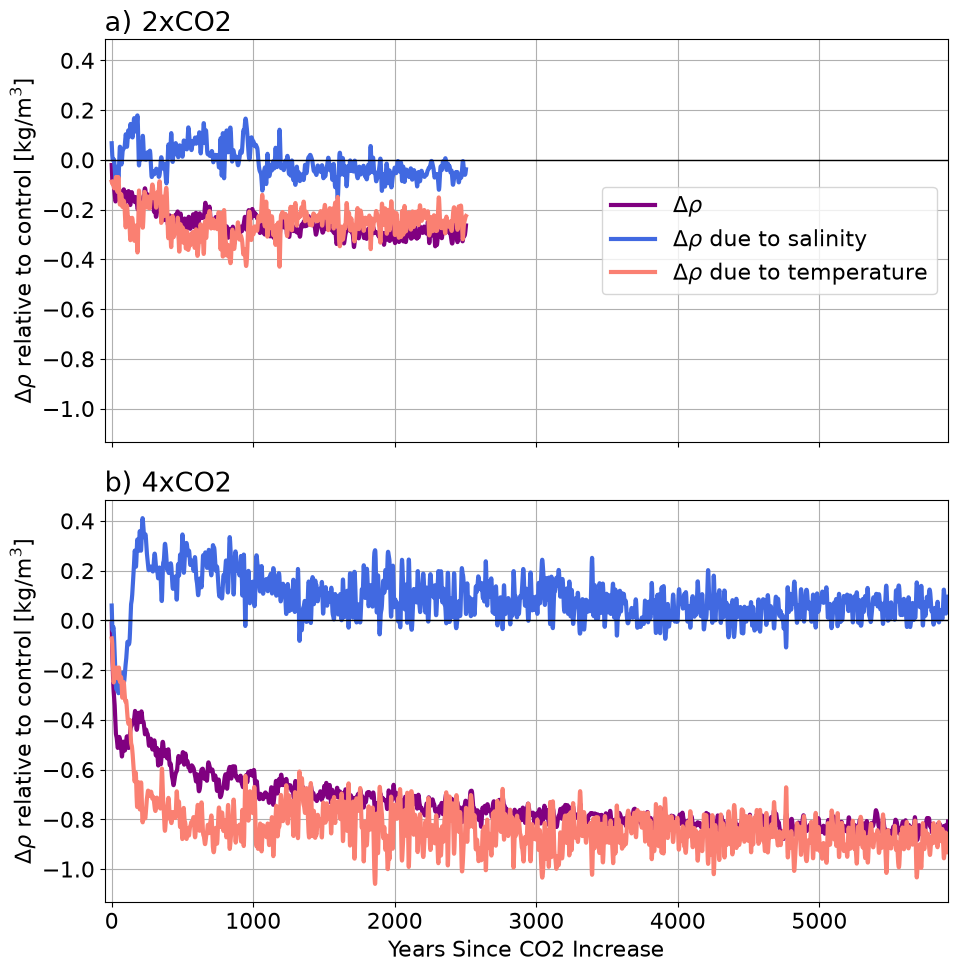

In [3]:
def plot_breakdown(ax, years, change, linewidth=3):
    """Draw the smoothed density change and its salinity and temperature parts on ax; zero is the control mean."""
    curves = [('total', '$\\Delta\\rho$', 'purple'),
              ('salinity', '$\\Delta\\rho$ due to salinity', 'royalblue'),
              ('temperature', '$\\Delta\\rho$ due to temperature', 'salmon')]
    for key, label, color in curves:
        ax.plot(years, common.butterworth_lowpass(change[key]), label=label, linewidth=linewidth, color=color)
    ax.axhline(0, color='k', linewidth=1)
    ax.grid()


fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True, sharey=True)
for ax, (panel_label, run) in zip(axes, [('a)', '2x'), ('b)', '4x')]):
    years, change = results[run]
    plot_breakdown(ax, years, change)
    ax.set_ylabel('$\\Delta\\rho$ relative to control [kg/m$^3$]')
    ax.set_title(f'{panel_label} {run}CO2', loc='left')

# The x range covers the longer 4x record, so the 2x curves stop where that run ends
axes[0].set_xlim(-common.X_START_PAD, results['4x'][0][-1])
axes[1].set_xlabel('Years Since CO2 Increase')
axes[0].legend(loc='center right')

fig.tight_layout()
plt.savefig(common.figure_path('figS2_density_breakdown_2x4x.png'), dpi=300, bbox_inches='tight')
plt.show()